# PPO tự chơi Super Mario Bros
Upload `mario_train_drive.zip` vào `MyDrive/Mario/`, rồi chạy từng ô từ trên xuống.
Notebook lấy mã `.py` từ ZIP trên Drive; train trên ổ cục bộ Colab và sao lưu checkpoint
lên Drive sau update đầu tiên, mỗi khoảng 5 phút và khi hoàn tất.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/')  # đổi nếu bạn lưu ở nơi khác
SOURCE_ZIP = DRIVE_ROOT / 'mario_train_drive.zip'
DRIVE_RUNS = DRIVE_ROOT / 'runs'
if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f'Hãy upload gói nguồn vào: {SOURCE_ZIP}')
print('Gói mã nguồn:', SOURCE_ZIP)
print('Nơi sao lưu:', DRIVE_RUNS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Gói mã nguồn: /content/drive/MyDrive/mario_train_drive.zip
Nơi sao lưu: /content/drive/MyDrive/runs


## 2. Lấy mã nguồn từ Drive

In [2]:
import os, sys, json, hashlib, tempfile, zipfile
if 'proc' in globals() and proc.poll() is None:
    raise RuntimeError('Train đang chạy; không đổi mã nguồn hoặc workspace.')
if any(name == 'mario_rl' or name.startswith('mario_rl.') for name in sys.modules):
    raise RuntimeError('Mã Mario đã được import. Dùng workspace hiện tại hoặc restart runtime để nạp gói mới.')
with zipfile.ZipFile(SOURCE_ZIP) as archive:
    manifest = json.loads(archive.read('MANIFEST.json'))
    names = archive.namelist()
    if len(names) != len(set(names)) or set(names) != set(manifest) | {'MANIFEST.json'}:
        raise ValueError('Danh sách file ZIP không khớp manifest')
    for name, item in manifest.items():
        path = Path(name)
        if path.is_absolute() or '..' in path.parts or '\\' in name:
            raise ValueError(f'Đường dẫn ZIP không hợp lệ: {name}')
        data = archive.read(name)
        if hashlib.sha256(data).hexdigest() != item['sha256']:
            raise ValueError(f'File bị thay đổi hoặc hỏng: {name}')
    WORK_DIR = Path(tempfile.mkdtemp(prefix='mario_', dir='/content'))
    archive.extractall(WORK_DIR)
os.chdir(WORK_DIR)
sys.path.insert(0, str(WORK_DIR))
(WORK_DIR / 'results').mkdir(exist_ok=True)
print('Chạy các file .py tại:', WORK_DIR)

Chạy các file .py tại: /content/mario_wrmfxla9


## 3. Cài thư viện và kiểm tra GPU

In [3]:
import os, subprocess
print(subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True).stdout or "Không có GPU")
print("Số CPU:", os.cpu_count())

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-e798e2d9-22f2-0d33-1d83-e3c1cced76a3)

Số CPU: 12


In [4]:
%%bash
set -e
pip -q install gym==0.26.2 tqdm
pip -q install nes-py==8.2.1 --no-deps
pip -q install gym-super-mario-bros==7.4.0 --no-deps
mkdir -p mario_rl scripts results

In [5]:
!python scripts/patch_nes_py_numpy2.py

import torch
assert torch.cuda.is_available(), 'Hãy chọn runtime GPU và kiểm tra PyTorch/CUDA'
print(torch.__version__, torch.version.cuda, torch.cuda.get_device_name(0))
x = torch.randn(32, 32, device='cuda')
print('CUDA kiểm tra:', (x @ x).mean().item())

# kiểm tra nhanh môi trường
import time, numpy as np
from mario_rl.envs import MarioEnv
env = MarioEnv(); obs = env.reset(); t0 = time.time(); n = 400
for _ in range(n):
    obs, r, done, info = env.step(np.random.randint(env.n_actions))
    if done:
        env.reset()
print("quan sát:", obs.shape, obs.dtype, f"| {n / (time.time() - t0):.0f} bước/giây (1 luồng)")
env.close()

Đã vá từ trước, không có gì để sửa.
2.11.0+cu130 13.0 NVIDIA A100-SXM4-40GB
CUDA kiểm tra: 0.2042611539363861
quan sát: (4, 84, 84) uint8 | 91 bước/giây (1 luồng)


## Cấu hình

In [6]:
import os, sys, time

RUN_NAME     = "ppo_1-1"
STAGES       = "1-1"            # nhiều màn: "1-1,1-2,1-3,1-4"
TOTAL_STEPS  = 3_000_000
REWARD_SCALE = 0.01
SEED         = 1
cpu          = os.cpu_count() or 1
NUM_ENVS     = 16 if cpu >= 10 else 8 if cpu >= 5 else 4 if cpu >= 3 else 2 if cpu >= 2 else 1
ROLLOUT_LEN  = 2048 // NUM_ENVS  # giữ lô = 2048 mẫu
OUT_DIR      = str(WORK_DIR / 'runs')  # train cục bộ, tự sao lưu sang Drive
RESUME       = False                  # True: khôi phục bản sao Drive mới nhất
BACKUP_INTERVAL = 300                  # giây, sao lưu ở cuối update

if not RUN_NAME or Path(RUN_NAME).name != RUN_NAME or RUN_NAME in ('.', '..'):
    raise ValueError('RUN_NAME phải là tên thư mục đơn')
DRIVE_RUN_DIR = DRIVE_RUNS / RUN_NAME
LOCAL_RUN_DIR = Path(OUT_DIR) / RUN_NAME
from mario_rl.drive_backup import restore_run
if RESUME:
    if not LOCAL_RUN_DIR.exists() or not any(LOCAL_RUN_DIR.iterdir()):
        restored = restore_run(DRIVE_RUN_DIR, LOCAL_RUN_DIR)
        print('Đã khôi phục:', restored)
    saved_cfg = json.loads((LOCAL_RUN_DIR / 'config.json').read_text())
    # Giữ nguyên cấu hình tương thích ngay cả khi runtime mới có số CPU khác.
    STAGES, REWARD_SCALE, SEED = (saved_cfg[k] for k in ('stages', 'reward_scale', 'seed'))
    NUM_ENVS, ROLLOUT_LEN = saved_cfg['num_envs'], saved_cfg['rollout_len']
elif DRIVE_RUN_DIR.exists() and any(DRIVE_RUN_DIR.iterdir()):
    raise FileExistsError('Run đã có trên Drive. Đổi RUN_NAME hoặc đặt RESUME=True.')

print(f"{NUM_ENVS} môi trường x {ROLLOUT_LEN} bước = {NUM_ENVS * ROLLOUT_LEN} mẫu/lần cập nhật")

16 môi trường x 128 bước = 2048 mẫu/lần cập nhật


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def plot_training(run_dir, ent_coef=0.01, vf_coef=0.5):
    """Vẽ kết quả chơi, các loss và chỉ số chẩn đoán PPO từ metrics.csv."""
    m = pd.read_csv(f"{run_dir}/metrics.csv")
    if len(m) < 3:
        print("Chưa đủ dữ liệu để vẽ.")
        return
    x = m["global_step"] / 1e6
    m["total_loss"] = m["policy_loss"] - ent_coef * m["entropy"] + vf_coef * m["value_loss"]
    groups = [
        ("Kết quả chơi", [("ep_return", "Return TB (100 ván gần nhất)"), ("ep_max_x", "x lớn nhất (pixel)"),
                          ("flag_rate", "Tỉ lệ chạm cờ")]),
        ("Hàm mất mát", [("total_loss", "Tổng loss"), ("policy_loss", "Policy loss"),
                         ("value_loss", "Value loss"), ("entropy", "Entropy của π")]),
        ("Chẩn đoán PPO", [("approx_kl", "KL xấp xỉ"), ("clip_frac", "Tỉ lệ bị clip"),
                           ("explained_var", "Explained variance"), ("lr", "Learning rate")]),
    ]
    for title, items in groups:
        fig, axes = plt.subplots(1, len(items), figsize=(4.3 * len(items), 3.1))
        for ax, (col, name) in zip(axes, items):
            ax.plot(x, m[col], color="tab:blue", alpha=0.25)
            ax.plot(x, m[col].rolling(10, min_periods=1).mean(), color="tab:blue")
            ax.set(title=name, xlabel="bước huấn luyện (triệu)")
        fig.suptitle(title, y=1.02)
        fig.tight_layout()
        plt.show()


def compare_runs(runs, labels, out_dir):
    """So sánh nhiều lần chạy (thí nghiệm đối chứng)."""
    cols = [("ep_max_x", "x lớn nhất (pixel)", False), ("flag_rate", "Tỉ lệ chạm cờ", False),
            ("value_loss", "Value loss", True), ("explained_var", "Explained variance", False)]
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
    for run, label in zip(runs, labels):
        m = pd.read_csv(f"{out_dir}/{run}/metrics.csv")
        for ax, (col, name, log) in zip(axes, cols):
            ax.plot(m["global_step"] / 1e6, m[col].rolling(5, min_periods=1).mean(), label=label)
            ax.set(title=name, xlabel="bước huấn luyện (triệu)")
            if log:
                ax.set_yscale("log")
    axes[0].legend()
    fig.tight_layout()
    plt.show()

## Huấn luyện

In [8]:
import subprocess

if "proc" in globals() and proc.poll() is None:
    raise RuntimeError(f"Train vẫn đang chạy (PID {proc.pid}); không khởi chạy thêm.")
os.makedirs(OUT_DIR, exist_ok=True)
cmd = [sys.executable, "-u", "train.py", "--run_name", RUN_NAME, "--out_dir", OUT_DIR, "--stages", STAGES,
       "--total_steps", str(TOTAL_STEPS), "--reward_scale", str(REWARD_SCALE), "--seed", str(SEED),
       "--num_envs", str(NUM_ENVS), "--rollout_len", str(ROLLOUT_LEN), "--resume", str(RESUME),
       "--drive_backup_dir", str(DRIVE_RUN_DIR), "--backup_interval", str(BACKUP_INTERVAL)]
if RESUME:
    # Chuyển tiếp cả các siêu tham số cũ không hiển thị trong ô cấu hình.
    explicit = {arg[2:] for arg in cmd if arg.startswith('--')}
    for name, value in saved_cfg.items():
        if name not in explicit and value is not None:
            cmd.extend([f'--{name}', str(value)])
log_path = f"{OUT_DIR}/{RUN_NAME}.log"
with open(log_path, "a") as train_log:
    proc = subprocess.Popen(cmd, stdout=train_log, stderr=subprocess.STDOUT)
print("Đã chạy nền, PID", proc.pid)

Đã chạy nền, PID 3663


Theo dõi trực tiếp (làm mới mỗi 30 giây). Bấm Stop để dừng theo dõi, huấn luyện vẫn chạy nền.

In [9]:
from IPython.display import clear_output

try:
    while proc.poll() is None:
        clear_output(wait=True)
        print("".join(open(log_path).readlines()[-3:]))
        if os.path.exists(f"{OUT_DIR}/{RUN_NAME}/metrics.csv"):
            try:
                plot_training(f"{OUT_DIR}/{RUN_NAME}")
            except pd.errors.EmptyDataError:
                print("Đang chờ dòng metrics đầu tiên.")
        time.sleep(30)
    clear_output(wait=True)
    print("Huấn luyện đã kết thúc.\n" + "".join(open(log_path).readlines()[-3:]))
    if proc.returncode != 0:
        raise RuntimeError(f"Train thất bại, exit code {proc.returncode}; xem {log_path}")
except KeyboardInterrupt:
    print("Đã dừng theo dõi (huấn luyện vẫn chạy nền).")

Huấn luyện đã kết thúc.
upd  1460/1464 | step  2,990,080 |   416 sps | ret   31.16 | x   3161 | flag 1.00 | ent 0.472 | kl 0.0000 | ev 1.00
[Drive backup final] /content/drive/MyDrive/runs/ppo_1-1/backup-1792950184530036575-step2998272.zip
Xong. Đã lưu vào /content/mario_wrmfxla9/runs/ppo_1-1



## Biểu đồ huấn luyện

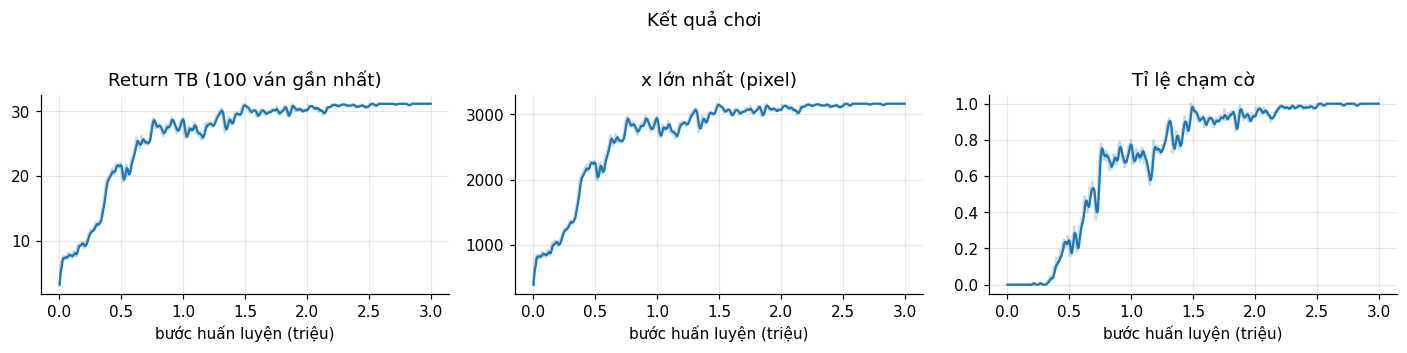

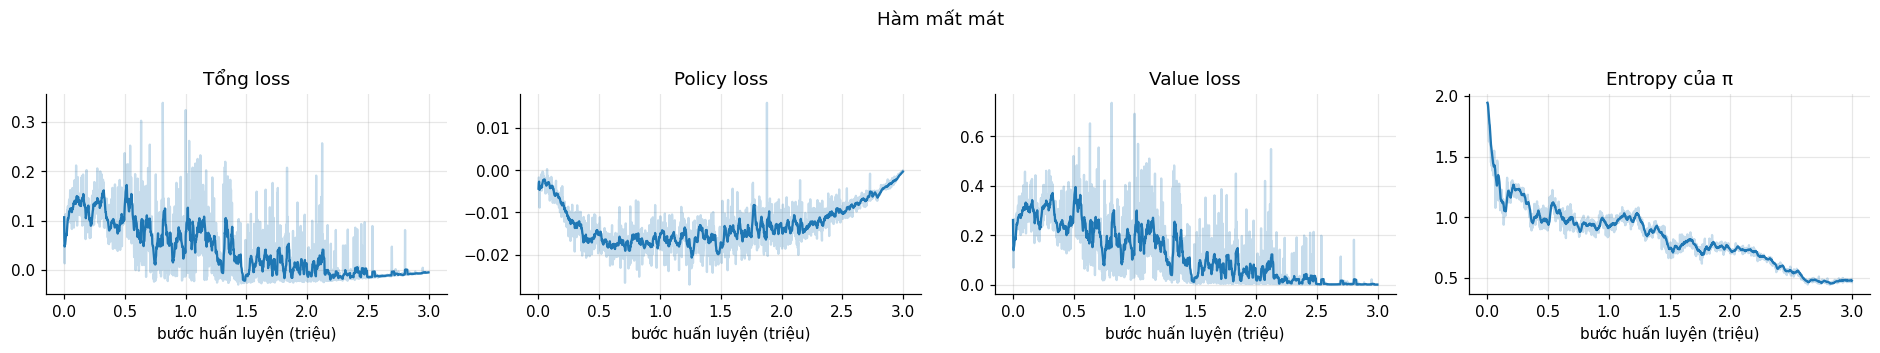

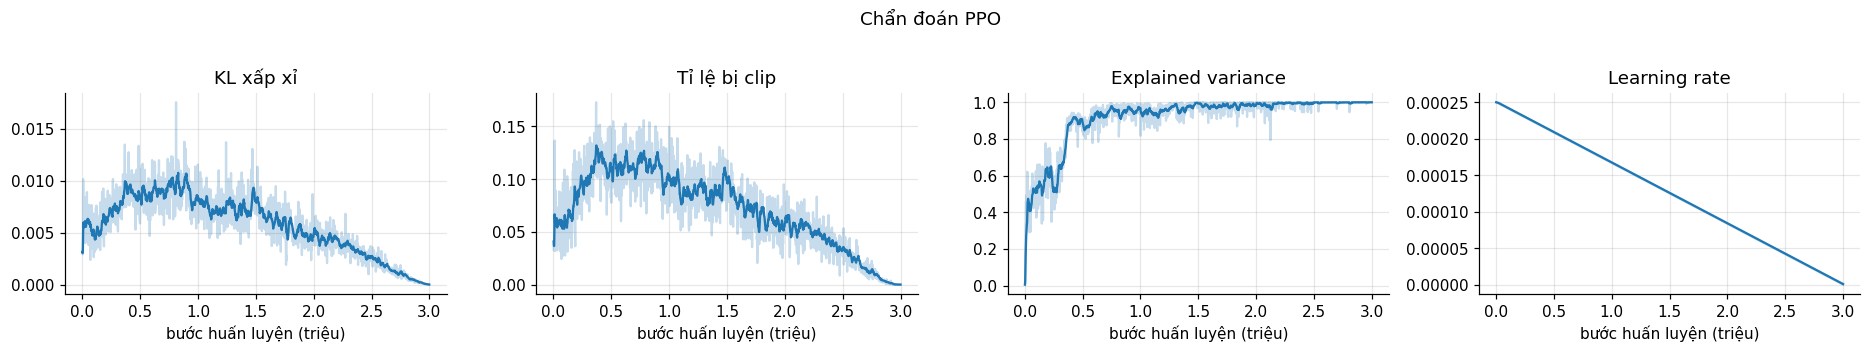

In [10]:
plot_training(f"{OUT_DIR}/{RUN_NAME}")

## Đánh giá

In [11]:
import numpy as np, torch
from mario_rl.evaluation import load_model, run_eval_vec, summarize
from mario_rl.models import ActorCritic

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = f"{OUT_DIR}/{RUN_NAME}/ckpt_final.pt"          # hoặc ckpt_best.pt
model, cfg = load_model(ckpt, device)
rand_model = ActorCritic(model.actor.out_features).to(device).eval()   # chưa huấn luyện: chính sách gần đều = ngẫu nhiên

settings = {
    "Ngẫu nhiên": (rand_model, dict(deterministic=False, noop_max=0)),
    "PPO: argmax, xuất phát lệch ngẫu nhiên": (model, dict(deterministic=True, noop_max=30)),
    "PPO: lấy mẫu từ π": (model, dict(deterministic=False, noop_max=0)),
}
eval_eps, rows = {}, {}
for name, (m, kw) in settings.items():
    eval_eps[name] = run_eval_vec(m, cfg, "1-1", episodes=100, device=device, **kw)
    rows[name] = summarize(eval_eps[name])
table = pd.DataFrame(rows).T[["flag_rate", "max_x_mean", "max_x_min", "return_mean", "clear_clock_ticks_mean"]]
table["return_tho"] = table["return_mean"] / cfg["reward_scale"]
table.to_csv("results/eval_table.csv")
table.round(3)

,flag_rate,max_x_mean,max_x_min,return_mean,clear_clock_ticks_mean,return_tho
Ngẫu nhiên,0.0,697.39,199.0,5.759,NaN,575.93
"PPO: argmax, xuất phát lệch ngẫu nhiên",1.0,3161.00,3161.0,31.169,54.52,3116.90
PPO: lấy mẫu từ π,1.0,3161.00,3161.0,31.162,54.11,3116.17


Kiểm chứng công thức phần thưởng cho ván về đích: return = c · [(x_cờ - 40) - (400 - t_còn) + b_cờ].

In [12]:
c, b = cfg["reward_scale"], cfg["flag_bonus"]
rows = []
for e in eval_eps["PPO: lấy mẫu từ π"]:          # ván xuất phát chuẩn (không có bước NOOP đầu ván)
    if e["flag"]:
        pred = c * ((e["max_x"] - 40) - (400 - e["time_left"]) + b)
        rows.append(dict(x_co=e["max_x"], t_con=e["time_left"], return_do=e["return"], du_doan=pred,
                         sai_lech=e["return"] - pred))
chk = pd.DataFrame(rows)
print("Số ván về đích:", len(chk), "| sai lệch tuyệt đối lớn nhất:", chk.sai_lech.abs().max() if len(chk) else None)
chk.to_csv("results/reward_formula_check.csv", index=False)
chk.head(10)

Số ván về đích: 100 | sai lệch tuyệt đối lớn nhất: 0.059999999999963194


,x_co,t_con,return_do,du_doan,sai_lech
0,3161,346,31.17,31.17,3.907985e-14
1,3161,346,31.17,31.17,3.907985e-14
2,3161,346,31.17,31.17,3.907985e-14
3,3161,346,31.17,31.17,3.907985e-14
4,3161,346,31.11,31.17,-6.000000e-02
5,3161,346,31.11,31.17,-6.000000e-02
6,3161,346,31.11,31.17,-6.000000e-02
7,3161,346,31.17,31.17,3.907985e-14
8,3161,346,31.17,31.17,3.907985e-14
9,3161,346,31.17,31.17,3.907985e-14


Tiến bộ theo từng checkpoint mốc.

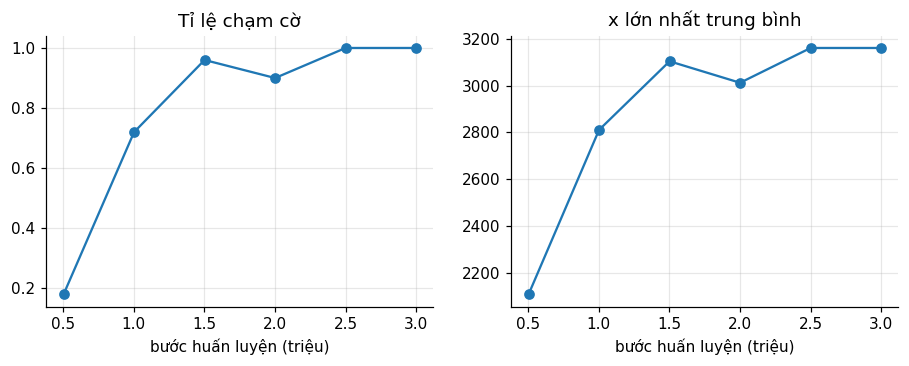

,step,flag_rate,max_x_mean
2,501760,0.18,2106.88
3,1001472,0.72,2810.58
1,1501184,0.96,3104.02
0,2000896,0.90,3012.16
4,2500608,1.00,3161.00
5,2998272,1.00,3161.00


In [13]:
import glob, re

paths = glob.glob(f"{OUT_DIR}/{RUN_NAME}/ckpt_*k.pt") + [f"{OUT_DIR}/{RUN_NAME}/ckpt_final.pt"]
rows = []
for p in paths:
    step = torch.load(p, map_location="cpu")["global_step"]
    m, _ = load_model(p, device)
    s = summarize(run_eval_vec(m, cfg, "1-1", episodes=50, deterministic=False, device=device))
    rows.append(dict(step=step, flag_rate=s["flag_rate"], max_x_mean=s["max_x_mean"]))
prog = pd.DataFrame(rows).sort_values("step")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(prog.step / 1e6, prog.flag_rate, "o-"); ax[0].set(title="Tỉ lệ chạm cờ", xlabel="bước huấn luyện (triệu)")
ax[1].plot(prog.step / 1e6, prog.max_x_mean, "o-"); ax[1].set(title="x lớn nhất trung bình", xlabel="bước huấn luyện (triệu)")
plt.show()
prog.to_csv("results/progress_by_checkpoint.csv", index=False)
prog

## Video

In [14]:
import shutil
from IPython.display import Image, Video, display
from mario_rl.evaluation import run_eval

run_eval(model, cfg, "1-1", episodes=1, deterministic=True, device=device, video_path="results/demo_1-1.mp4",
         gif_path="results/demo_1-1.gif", gif_every=4, max_steps=700)
if shutil.which("ffmpeg"):  # mp4 chuẩn H.264 để phát trong trình duyệt
    !ffmpeg -y -loglevel error -i results/demo_1-1.mp4 -vcodec libx264 -pix_fmt yuv420p results/demo_1-1_h264.mp4
    display(Video("results/demo_1-1_h264.mp4", embed=True, width=512))
else:
    display(Image(filename="results/demo_1-1.gif"))

## Tuỳ chọn: chơi thử màn khác (agent chỉ học 1-1)

In [15]:
rows = {}
for stage in ["1-2", "1-3", "1-4", "2-1"]:
    rows[stage] = summarize(run_eval_vec(model, cfg, stage, episodes=30, deterministic=False, device=device))
gen = pd.DataFrame(rows).T[["flag_rate", "max_x_mean", "max_x_min"]].round(3)
gen.to_csv("results/generalization.csv")
gen

,flag_rate,max_x_mean,max_x_min
1-2,0.0,395.067,143.0
1-3,0.0,369.433,284.0
1-4,0.0,371.133,226.0
2-1,0.0,647.767,370.0


## Tuỳ chọn: đối chứng thang phần thưởng (0,1 so với 0,01), mỗi lần 600k bước

upd   285/292 | step    583,680 |   420 sps | ret   97.05 | x   1057 | flag 0.00 | ent 0.922 | kl 0.0110 | ev 0.69
upd   290/292 | step    593,920 |   420 sps | ret   92.72 | x   1011 | flag 0.00 | ent 0.950 | kl 0.0092 | ev 0.70
Xong. Đã lưu vào /content/mario_wrmfxla9/runs/pilot_scale0.1
upd   285/292 | step    583,680 |   421 sps | ret   19.45 | x   2040 | flag 0.16 | ent 0.994 | kl 0.0112 | ev 0.90
upd   290/292 | step    593,920 |   421 sps | ret   20.22 | x   2119 | flag 0.19 | ent 0.941 | kl 0.0093 | ev 0.85
Xong. Đã lưu vào /content/mario_wrmfxla9/runs/pilot_scale0.01


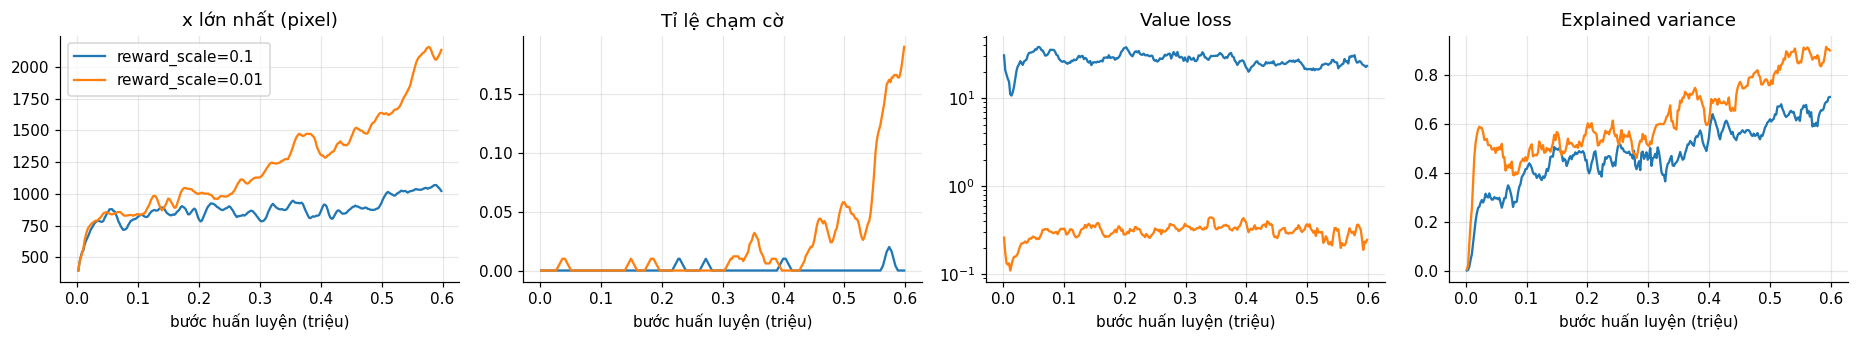

In [16]:
names = {}
for scale in (0.1, 0.01):
    name = f"pilot_scale{scale}"
    names[name] = f"reward_scale={scale}"
    !python -u train.py --run_name {name} --out_dir {OUT_DIR} --total_steps 600000 --anneal_lr false --reward_scale {scale} --snapshot_every 1000000000 --num_envs {NUM_ENVS} --rollout_len {ROLLOUT_LEN} | tail -n 3
compare_runs(list(names), list(names.values()), OUT_DIR)

## Lưu toàn bộ kết quả lên Drive (chạy sau train/đánh giá)

In [17]:
import zipfile, time, shutil
from mario_rl.drive_backup import digest
assert proc.poll() is not None, 'Train vẫn chạy; hãy chờ hoàn tất'
export = WORK_DIR / f'{RUN_NAME}_results_{time.time_ns()}.zip'
with zipfile.ZipFile(export, 'w', zipfile.ZIP_DEFLATED) as archive:
    for folder in (Path(OUT_DIR), WORK_DIR / 'results'):
        for path in folder.rglob('*'):
            if path.is_file() and path.name != '.train.lock' and not path.name.endswith(('.tmp', '.pending.zip')):
                archive.write(path, path.relative_to(WORK_DIR))
DRIVE_RUN_DIR.mkdir(parents=True, exist_ok=True)
target = DRIVE_RUN_DIR / export.name
shutil.copyfile(export, target)
assert digest(export) == digest(target), 'Bản sao kết quả không khớp'
print('Đã lưu cả checkpoint, CSV và video:', target)

Đã lưu cả checkpoint, CSV và video: /content/drive/MyDrive/runs/ppo_1-1/ppo_1-1_results_1792953843954287810.zip
